# Step 9: compare all models that have been run (reads results/metrics_*.json).

In [1]:
# Run from the project root so data/, figures/ and results/ paths work
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%matplotlib inline

In [2]:
import glob
import json

import matplotlib.pyplot as plt
import pandas as pd

SCRIPTS = {"xgboost": "04_xgboost.py", "keras": "05_keras.py", "fastai": "06_fastai.py",
           "tabnet": "07_tabnet.py", "lightning_flash": "08_lightning_flash.py"}

rows = [json.load(open(f)) for f in sorted(glob.glob("results/metrics_*.json"))]
if not rows:
    raise SystemExit("No results yet - run the model scripts first.")
df = pd.DataFrame(rows).set_index("model").drop(columns=["best_params"], errors="ignore")


def code_lines(script):
    """Non-blank, non-comment lines: a rough, objective measure of simplicity."""
    try:
        with open(script) as f:
            return sum(1 for l in f if l.strip() and not l.strip().startswith(("#", '"""')))
    except FileNotFoundError:
        return None


df["lines_of_code"] = [code_lines(SCRIPTS.get(m, "")) for m in df.index]
df["beats_baseline_RMSE"] = df["RMSE"] < df["Baseline_RMSE"]

cols = ["RMSE", "MAE", "R2", "Directional_Accuracy", "Baseline_RMSE",
        "Baseline_Directional_Accuracy", "beats_baseline_RMSE", "train_seconds",
        "lines_of_code", "expected_weekly_return_pct", "expected_annualised_return_pct"]
table = df[[c for c in cols if c in df.columns]].sort_values("RMSE")
table.to_csv("results/comparison.csv")
pd.set_option("display.width", 200)
print(table.round(4).to_string())

                   RMSE     MAE      R2  Directional_Accuracy  Baseline_RMSE  Baseline_Directional_Accuracy  beats_baseline_RMSE  train_seconds  lines_of_code  expected_weekly_return_pct  expected_annualised_return_pct
model                                                                                                                                                                                                                     
fastai           0.0367  0.0252  0.0346                0.5928         0.0374                         0.5629                 True           2.73             43                      1.6064                        129.0334
lightning_flash  0.0373  0.0262  0.0056                0.6168         0.0374                         0.5629                 True           1.14             47                      0.4799                         28.2682
keras            0.0373  0.0259  0.0053                0.6108         0.0374                         0.5629                 

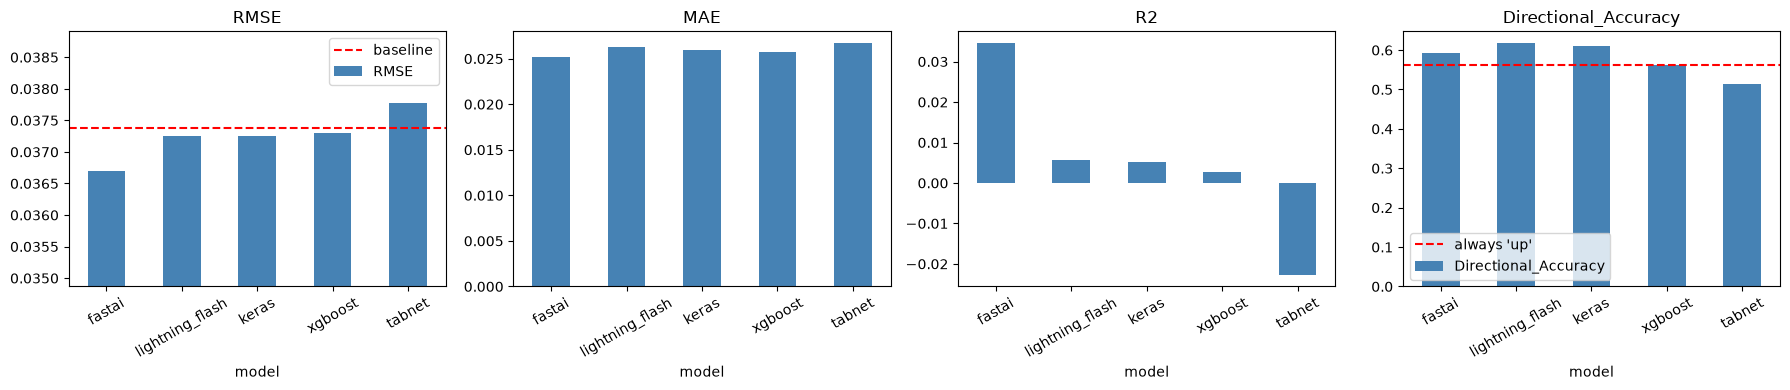

In [3]:
# Metric bar charts
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, ["RMSE", "MAE", "R2", "Directional_Accuracy"]):
    table[m].plot.bar(ax=ax, color="steelblue", title=m)
    if m == "RMSE":
        ax.axhline(table["Baseline_RMSE"].iloc[0], color="red", ls="--", label="baseline")
        ax.set_ylim(table["RMSE"].min() * 0.95, table["RMSE"].max() * 1.03); ax.legend()
    if m == "Directional_Accuracy":
        ax.axhline(table["Baseline_Directional_Accuracy"].iloc[0], color="red", ls="--",
                   label="always 'up'"); ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/comparison_metrics.png", dpi=120); plt.show()

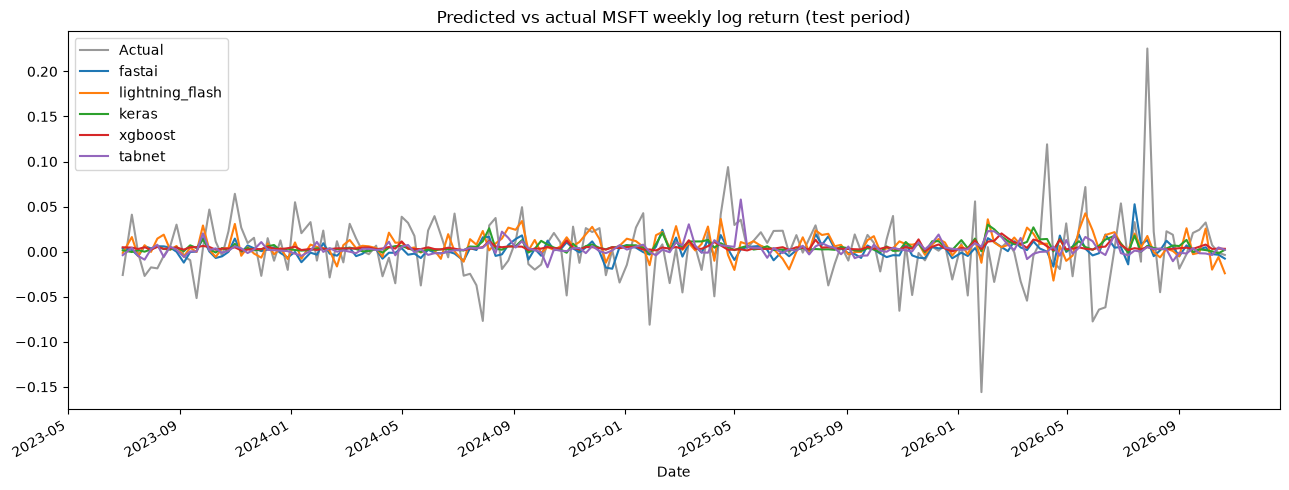


Saved results/comparison.csv, figures/comparison_metrics.png, figures/comparison_predictions.png
Simplicity / transparency ratings are your own judgement - write them up in the report.


In [4]:
# Predicted vs actual, all models on one chart
preds = {m: pd.read_csv(f"results/predictions_{m}.csv", index_col=0, parse_dates=True)
         for m in table.index}
ax = next(iter(preds.values()))["actual"].plot(figsize=(13, 5), color="black", alpha=0.4, label="Actual")
for m, p in preds.items():
    p["predicted"].plot(ax=ax, label=m)
ax.set_title("Predicted vs actual MSFT weekly log return (test period)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/comparison_predictions.png", dpi=120); plt.show()

print("\nSaved results/comparison.csv, figures/comparison_metrics.png, figures/comparison_predictions.png")
print("Simplicity / transparency ratings are your own judgement - write them up in the report.")